# TP2 : Estimation de densité par noyaux

## G3 SDI - Introduction à l'Estimation Statistique

Dans le cadre du cours, nous avons étudié jusqu'à présent des méthodes d'estimation dites paramétriques : on se fixe une famille de lois paramétrique à laquelle la loi ayant généré les données est censée appartenir, puis on cherche à estimer les paramètres à partir des données (par exemple par maximum de vraisemblance).

Dans ce TP, nous introduisons une méthode d'estimation **non-paramétrique** de la fonction de densité appelée estimation par noyaux (*kernel estimation* en anglais). C'est-à-dire que nous ne faisons plus d'hypothèse sur la loi ayant généré les données, et nous cherchons plutôt à estimer directement la densité de la loi parente $f$ (que l'on supposera continue). Ainsi cette méthode ne concerne que les variables aléatoires continues.

### Instructions

1. Renommez votre notebook sous la forme `tp2_Nom1_Nom2.ipynb`. 

2. Votre code et les résultats obtenus doivent être commentés !

3. Déposez votre notebook sur Moodle dans la section prévue à cet effet avant la date limite.

<div style="background-color: rgba(255, 255, 0, 0.15); padding: 8px;">
Compte-rendu écrit par [nom1], [nom2], date.
</div>

In [50]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats as ss
import seaborn
from sklearn.neighbors import KernelDensity
from sklearn.model_selection import GridSearchCV, LeaveOneOut
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.datasets import load_digits

### Partie 1 - Histogrammes

On considère $(x_1, ..., x_n)$ $n$ réalisations indépendantes d'une variable aléatoire réelle.

Soit $x_0 \in \mathbb{R}$ et $h > 0$. On partitionne la droite réelle en intervalles de même longueur $h$, aussi appelés *bins* :
$$\forall k \in \mathbb{Z},~B_k =~]x_0 + (k-1)h~;~x_0 + kh].$$

L'histogramme est une fonction constante par morceaux définie de la manière suivante :
$$\forall x \in B_k,~H_n(x) = n_k,$$
où $n_k$ est le nombre de réalisations appartenant à l'intervalle $B_k$.

**Q1**. Comment normaliser $H_n$ pour obtenir un estimateur de la fonction de densité ? On rappelera que $\int_{\mathbb{R}} f(x) dx = 1$.

Dans la suite, on note $\hat{f}_n$ cet estimateur de $f$.

<div style="background-color: rgba(255, 255, 0, 0.15); padding: 8px;">

Par construction, $\int_{\mathbb{R}} H_n(x)\,dx = \sum_k n_k\,h = nh$. Pour obtenir une densité, on divise par $nh$ :
$$\hat{f}_n(x) = \frac{H_n(x)}{nh} = \frac{n_k}{nh} \quad \text{pour } x \in B_k.$$
Ici $n_k/n$ est la fréquence empirique de $B_k$, qui estime $p_k = \int_{B_k} f \approx h\,f(x)$.

</div>

**Q2 (bonus).** Pour tout $x \in \mathbb{R}$, calculer le biais et la variance de $\hat{f}_n(x)$. Commenter.

<div style="background-color: rgba(255, 255, 0, 0.15); padding: 8px;">

Soit $x \in B_k = \,]a_k, a_k+h]$ et $p_k = \int_{B_k} f$. Alors $n_k \sim \mathrm{Bin}(n, p_k)$, donc on peut tout calculer : 

- **Espérance** : $\mathbb{E}[\hat f_n(x)] = p_k/h$.
- **Biais** : $\dfrac{p_k}{h} - f(x) = \dfrac1h\displaystyle\int_{B_k}\big(f(t)-f(x)\big)dt \approx f'(x)\,\big(a_k + \tfrac h2 - x\big)$ (Taylor à l'ordre 1), donc $|\text{biais}| \lesssim \tfrac h2 |f'(x)| = O(h)$.
- **Variance** : $\dfrac{p_k(1-p_k)}{nh^2} \approx \dfrac{f(x)}{nh}$, car $p_k \approx h f(x)$.

Lorsque $h$ diminue, le biais diminue mais la variance augmente (et inversement) : c'est le compromis biais-variance. L'estimateur est convergent si $h \to 0$ et $nh \to \infty$.

</div>

**Q3**. On fixe $x_0 = \min_i x_i$. La valeur de $h$ peut être fixée indirectement en fixant à la place le nombre de *bins* $N_b$ entre $\min_i x_i$ et $\max_i x_i$, on a alors
$$h = \frac{\max_i x_i - \min_i x_i}{N_b}.$$

Générer 200 points d'un modèle de mélange gaussien 1D à 2 composantes avec $\mu_1 = -2.5, \mu_2 = 1.5, \sigma_1 = \sigma_2 = 1, \pi_1 = 0.4, \pi_2 = 0.6$.

Montrer l'influence de la valeur de $h$ sur l'histogramme normalisé (prendre les valeurs de Nb suggérées dans la cellule de code).

On utilisera la fonction `np.histogram` pour calculer automatiquement les $n_k$, et la fonction `plt.bar` pour représenter $\hat{f}_n$. Superposer la densité théorique du modèle de mélange gaussien. Commenter.

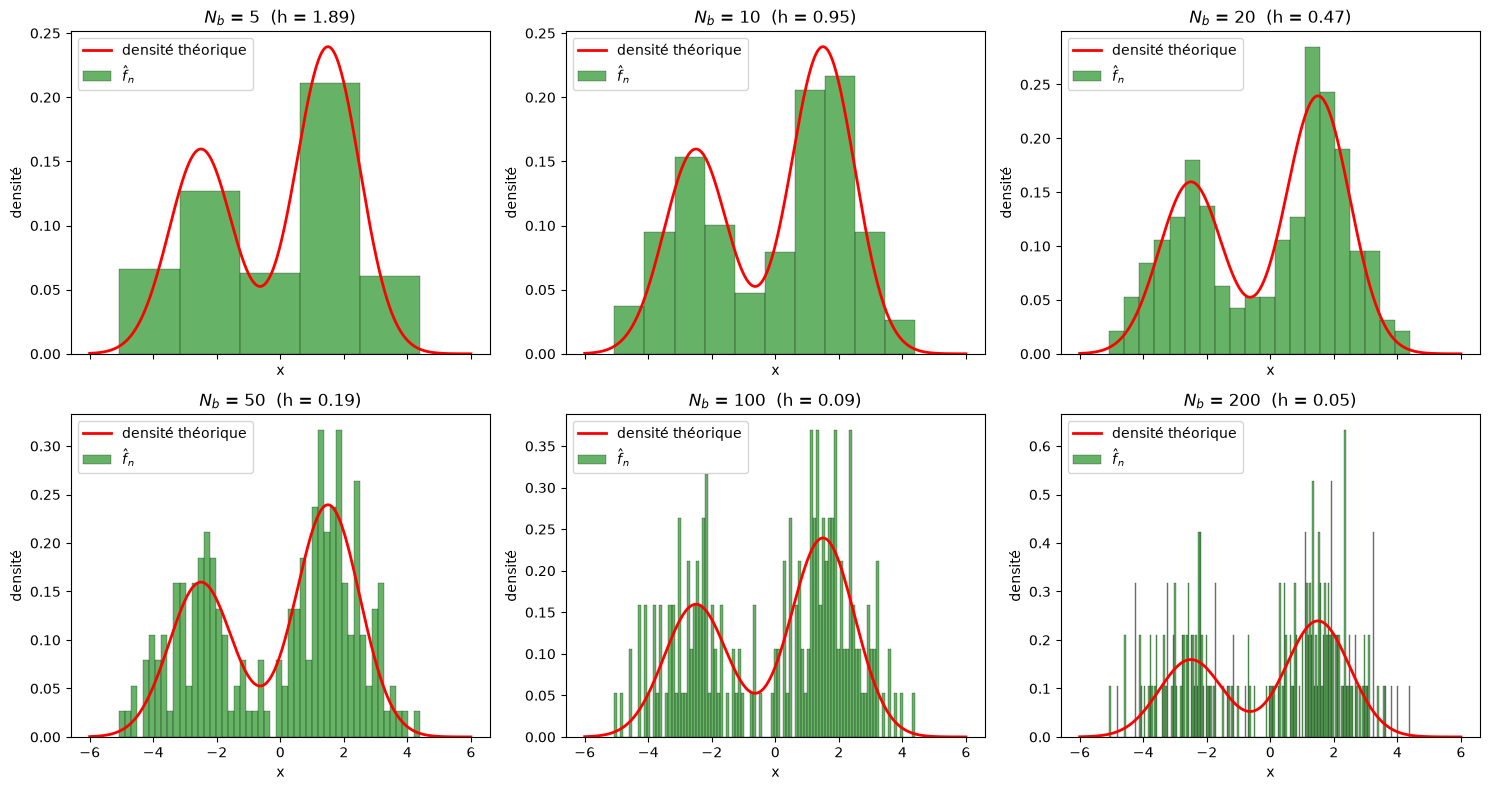

In [51]:
N = 200
rng = np.random.default_rng(seed=42)

mu = np.array([-2.5, 1.5])
sigma = np.array([1.0, 1.0])
pi = np.array([0.4, 0.6])

# Échantillonnage du GMM : on tire la composante, puis la valeur gaussienne associée
labels = rng.choice(2, size=N, p=pi)
Z = rng.normal(mu[labels], sigma[labels])

# Densité théorique sur une grille fine
xs = np.linspace(-6, 6, 1000)
f_true = sum(p * ss.norm.pdf(xs, m, s) for p, m, s in zip(pi, mu, sigma))

Nb_list = [5, 10, 20, 50, 100, 200]
fig, axes = plt.subplots(2, 3, figsize=(15, 8), sharex=True)
for ax, Nb in zip(axes.ravel(), Nb_list):
    nk, edges = np.histogram(Z, bins=Nb)   # x0 = min(Z), h = (max - min) / Nb
    h = edges[1] - edges[0]
    f_hat = nk / (N * h)                   # normalisation de la Q1
    assert np.isclose(np.sum(f_hat * h), 1)  # l'histogramme intègre bien à 1
    ax.bar(edges[:-1], f_hat, width=h, align='edge', alpha=0.6, color='g', edgecolor='k', lw=0.3,
           label=r'$\hat f_n$')
    ax.plot(xs, f_true, 'r-', lw=2, label='densité théorique')
    ax.set_title(f'$N_b$ = {Nb}  (h = {h:.2f})')
    ax.set_xlabel('x'); ax.set_ylabel('densité'); ax.legend()
plt.tight_layout()
plt.show()


<div style="background-color: rgba(255, 255, 0, 0.15); padding: 8px;">

- **$N_b = 5$** ($h$ grand) : trop lisse, les bins sont si larges que le creux entre les deux modes du mélange est écrasé et que la position des modes est imprécise. Ici, gros biais, faible variance.
  
- **$N_b = 10$ à $20$** : bon compromis, la bimodalité et les poids relatifs des deux composantes sont bien retrouvés.
  
- **$N_b \geq 50$** ($h$ petit) : l'histogramme devient bruité, avec de nombreux bins quasi vides et des pics isolés. Pour $N_b = 200$, on a environ un point par bin. Ici, grosse variance, faible biais, clairement en situation d'overfitting.

h est le paramètre crucial pour résoudre le tradeoff

</div>

**Q4**. Quelles sont les principales limitations de l'utilisation de l'histogramme comme estimateur de la fonction de densité ?

<div style="background-color: rgba(255, 255, 0, 0.15); padding: 8px;">

- **Dépendance à des choix arbitraires** : l'origine $x_0$ et la largeur $h$ changent l'allure de l'histogramme pour les mêmes données.
- **Estimateur discontinu**, constant par morceaux, alors que $f$ est supposée continue : les dérivées sont nulles presque partout ou inexistantes.
- **Curse of dimensionality** : en dimension $d$, il y a $N_b^d$ cases, presque toutes vides.
- **Largeur fixe** : trop fine dans les queues et trop grossière dans les zones denses.
  
</div>

### Partie 2 - Estimation par noyaux en 1D

$(x_1, ..., x_n)$ sont toujours $n$ réalisations indépendantes d'une variable aléatoire réelle.

L'une des motivations principales est de faire directement dépendre l'estimation des données, et de ne plus dépendre de découpages arbitraires de $\mathbb{R}$. Pour cela, on propose la méthodologie suivante :
- Choisir une fonction $K$ appelée "noyau". On choisit $K$ positive ou nulle, symétrique, et d'intégrale 1.
- Centrer $K$ sur chaque observation $x_i$.
- L'estimateur à noyaux est alors
$$\hat{f}_n(x) = \frac{1}{n} \sum_{i=1}^n K(x - x_i).$$

On pourra par exemple choisir des noyaux $K$ continus, dérivables partout... Propriétés dont $\hat{f}_n$ héritera.

**Q1**. On utilise dans un premier temps un noyau gaussien :
$$K(x) = \frac{1}{\sqrt{2 \pi}} \exp \left( -\frac{x^2}{2} \right).$$

Prendre 10 observations des données générées dans la partie 1. Sur un même graphique, représenter les 10 noyaux (normalisés par $n$) centrés sur les observations, et l'estimateur à noyaux $\hat{f}_n$. Superposer la vraie densité $f$. Commenter.

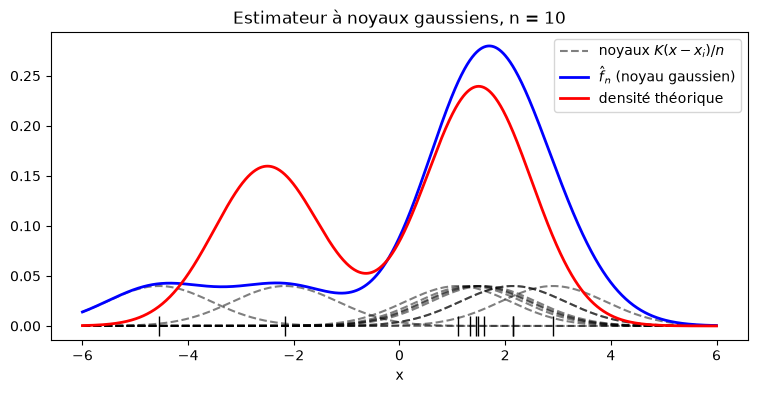

In [52]:
# Randomly select 10 points from previously generated dataset
def K_gauss(u):
    return np.exp(-u**2 / 2) / np.sqrt(2 * np.pi)

Z10 = Z[:10]


# Implement the kernel density estimator and plot it

def K_gauss(u):
    return np.exp(-u**2 / 2) / np.sqrt(2 * np.pi)

n10 = len(Z10)

# Chaque noyau K(x - x_i) est normalisé par n : matrice (len(xs), 10)
kernels = K_gauss(xs[:, None] - Z10[None, :]) / n10
f_hat10 = kernels.sum(axis=1)     # estimateur = somme des 10 noyaux

plt.figure(figsize=(9, 4))
plt.plot(xs, kernels[:, 0], 'k--', alpha=0.5, label=r'noyaux $K(x-x_i)/n$')
plt.plot(xs, kernels[:, 1:], 'k--', alpha=0.5)
plt.plot(xs, f_hat10, 'b-', lw=2, label=r'$\hat f_n$ (noyau gaussien)')
plt.plot(xs, f_true, 'r-', lw=2, label='densité théorique')
plt.plot(Z10, np.zeros(n10), 'k|', ms=15)          # positions des observations
plt.title('Estimateur à noyaux gaussiens, n = 10')
plt.xlabel('x'); plt.legend(); plt.show()

<div style="background-color: rgba(255, 255, 0, 0.15); padding: 8px;">

Chaque observation apporte une « bosse » de masse $1/n$. Avec seulement $n = 10$ points, il est cependant peu fiable. Ici, seuls 2 points sur 10 tombent dans le mode de gauche (contre 4 attendus en moyenne) : ce mode est donc sous-estimé et mal centré, tandis que le mode de droite est surestimé. Le résultat dépend fortement des quelques points tirés.

</div>

**Q2**. En réalité, on va faire dépendre cet estimateur d'un paramètre de lissage $h > 0$, qu'on appelle largeur de fenêtre (ou *bandwidth* en anglais).

Le (véritable) estimateur à noyaux, aussi appelé méthode de Parzen-Rosenblatt (du nom des deux statisticiens l'ayant développée) est :
$$\hat{f}_n(x) = \frac{1}{nh} \sum_{i=1}^n K(\frac{x - x_i}{h}).$$

(On peut facilement vérifier que $\hat{f}_n(x)$ intègre bien à 1).

Implémenter cet estimateur sur les données générées dans la partie 1, et montrer l'influence de la valeur de $h$. Commenter.

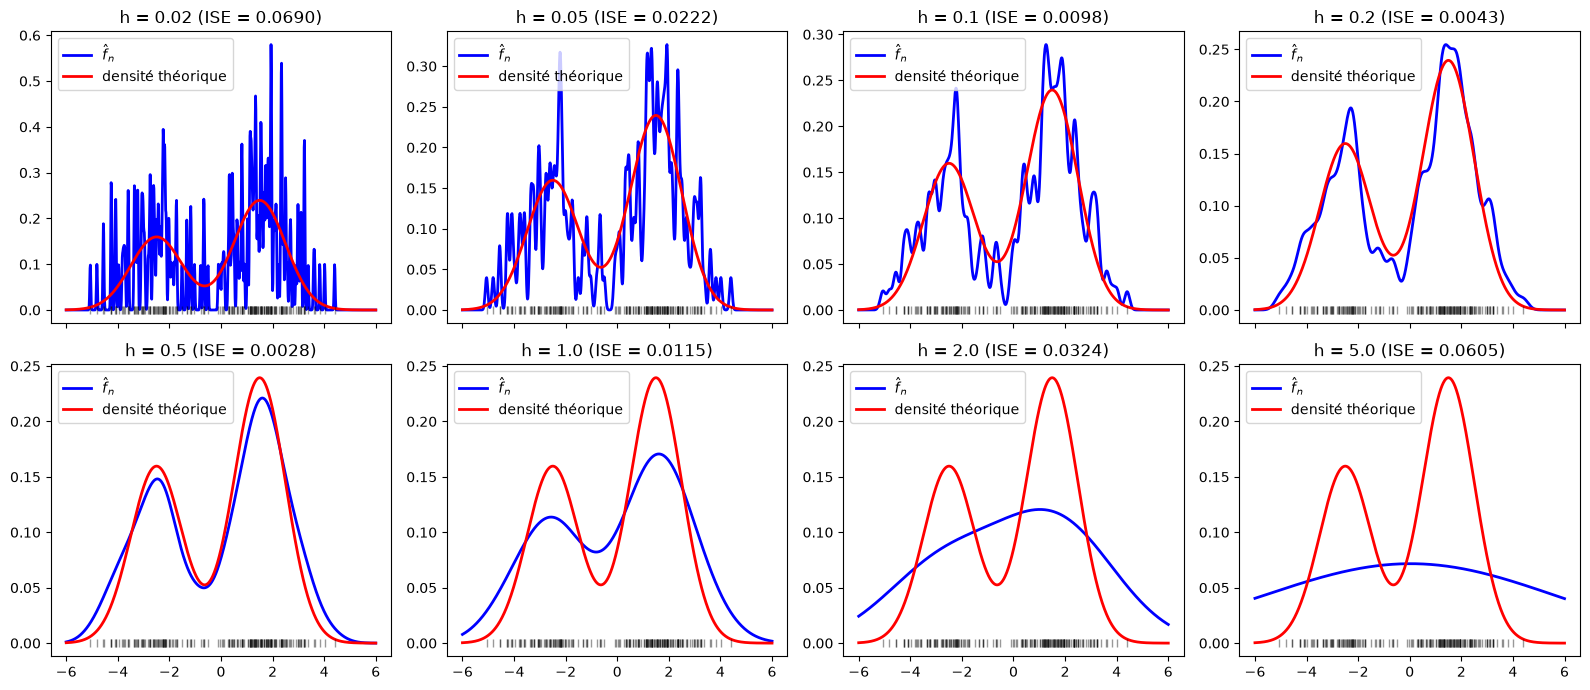

In [59]:

# Implement the kernel density estimator and plot it
h_list = [0.01, 0.002, 0.1, 0.2, 0.3, 0.5, 0.7, 0.75, 0.8, 1.0, 1.5, 2.0, 5, 10, 20]

def kde_1d(x, data, h, K=K_gauss):
    """Estimateur de Parzen-Rosenblatt : (1 / (n h)) * sum_i K((x - x_i) / h)."""
    return K((x[:, None] - data[None, :]) / h).sum(axis=1) / (len(data) * h)

h_list = [0.02, 0.05, 0.1, 0.2, 0.5, 1.0, 2.0, 5.0]
fig, axes = plt.subplots(2, 4, figsize=(16, 7), sharex=True)
for ax, h in zip(axes.ravel(), h_list):
    f_hat = kde_1d(xs, Z, h)
    ise = np.trapezoid((f_hat - f_true) ** 2, xs)   # erreur quadratique intégrée (f connue ici)
    ax.plot(xs, f_hat, 'b-', lw=2, label=r'$\hat f_n$')
    ax.plot(xs, f_true, 'r-', lw=2, label='densité théorique')
    ax.plot(Z, np.zeros(len(Z)), 'k|', alpha=0.4)
    ax.set_title(f'h = {h} (ISE = {ise:.4f})')
    ax.legend()
plt.tight_layout()
plt.show()


<div style="background-color: rgba(255, 255, 0, 0.15); padding: 8px;">

- **$h$ très petit** ($\leq 0.05$) : un pic étroit sur chaque observation (le cas limite $h \to 0$ est une somme de Diracs). La variance est énorme et l'estimateur est très irrégulier.
- **$h$ intermédiaire** ($\approx 0.3$ à $0.5$) : estimation proche de la vraie densité, avec les deux modes bien retrouvés.
- **$h$ grand** : à $h = 1$ la bimodalité est encore visible mais trop aplatie, et à partir de $h = 2$ les deux modes fusionnent. Le biais domine.

C'est le même compromis biais-variance qu'avec les histogrammes, mais l'estimateur est ici **continu** et ne dépend plus d'une origine $x_0$.

</div>

**Q3.** Nous allons maintenant regarder d'autres noyaux. Cette fois-ci, nous n'implémenterons pas l'estimateur à la main mais ferons appel à la librairie `scikit-learn` qui implémente six noyaux différents (dont le noyau gaussien). La méthode est implémentée dans `sklearn.neighbors.KernelDensity` (voir la doc [ici](https://scikit-learn.org/stable/modules/generated/sklearn.neighbors.KernelDensity.html)).

Représenter les six noyaux. Commenter.

À longueur de fenêtre fixée (par exemple $h = 0.5$), montrer l'influence des différentes fenêtres. Commenter.

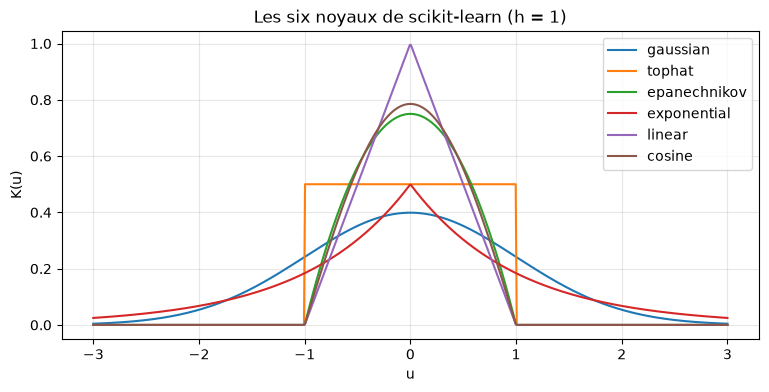

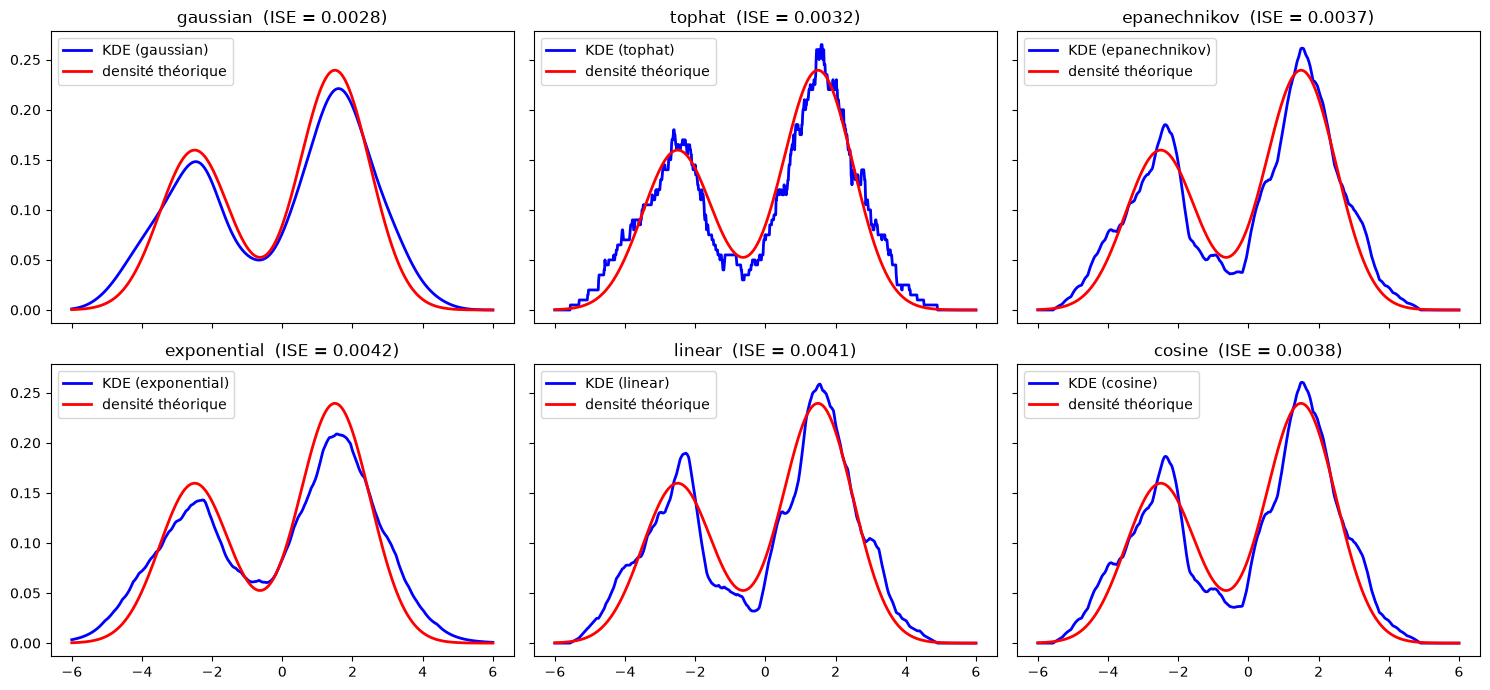

In [58]:
# Represent the 6 different kernels implemented in scikit-learn

kernel_names = ['gaussian', 'tophat', 'epanechnikov', 'exponential', 'linear', 'cosine']

u = np.linspace(-3, 3, 600)
plt.figure(figsize=(9, 4))
for k in kernel_names:
    kde_k = KernelDensity(kernel=k, bandwidth=1.0).fit([[0.0]])   # un seul point en 0 => on obtient le noyau
    plt.plot(u, np.exp(kde_k.score_samples(u[:, None])), label=k)
plt.title('Les six noyaux de scikit-learn (h = 1)')
plt.xlabel('u'); plt.ylabel('K(u)'); plt.legend(); plt.grid(alpha=0.3); plt.show()

# Show the influence of the kernel (with fixed bandwidth)

fig, axes = plt.subplots(2, 3, figsize=(15, 7), sharex=True, sharey=True)
for ax, k in zip(axes.ravel(), kernel_names):
    dens = np.exp(KernelDensity(kernel=k, bandwidth=0.5).fit(Z[:, None]).score_samples(xs[:, None]))
    ise = np.trapezoid((dens - f_true) ** 2, xs)
    ax.plot(xs, dens, 'b-', lw=2, label=f'KDE ({k})')
    ax.plot(xs, f_true, 'r-', lw=2, label='densité théorique')
    ax.set_title(f'{k}  (ISE = {ise:.4f})')
    ax.legend()
plt.tight_layout()
plt.show()

<div style="background-color: rgba(255, 255, 0, 0.15); padding: 8px;">

Tous les noyaux sont positifs, symétriques et d'intégrale 1. `gaussian` et `exponential` ont un support infini, les quatre autres un support borné. Leur régularité diffère : `gaussian` est $C^\infty$, `cosine`, `linear` et `epanechnikov` sont continus mais avec des points anguleux, `exponential` a une pointe en 0, et `tophat` est discontinu.

$\hat f_n$ hérite de la régularité du noyau , mais les ISE restent du même ordre de grandeur (entre 0.003 et 0.004) : le choix du noyau a une influence bien plus faible que celui de $h$. On le choisit surtout pour la régularité souhaitée et le coût de calcul vraisemblablement.

</div>

**Q4 (bonus)**. La question du choix de $h$ a été largement étudiée dans la littérature. Par exemple, la librairie `scikit-learn` embarque pour l'argument *bandwidth* deux règles de calcul empiriques appelées règle de Scott et règle de Silvermann, qui fixent la valeur de $h$ en fonction de $n$ et $d$ (la dimension des données).

À l'aide d'une notion du cours, pouvez-vous imaginer un critère d'optimalité permettant de fixer la valeur de $h$ ?

<div style="background-color: rgba(255, 255, 0, 0.15); padding: 8px;">
----- Votre réponse ici -----
</div>

### Partie 3 : Estimation par noyaux en 2D

L'estimation de densité par noyaux peut être étendue en $d$ dimensions. On peut alors définir $\mathbf{H}$ une matrice symmétrique de taille $d \times d$ définie positive pour les longueurs de fenêtres (NB : `scikit-learn` ne le permet pas et n'a qu'un paramètre scalaire en $d$ dimensions).

**Q1**. Reprendre le dataset *Old Faithful* étudié au TP1, et faire une estimation par noyaux de la densité en utilisant `scikit-learn`. Le choix du noyau et de la longueur de fenêtre est laissé libre.

Afficher la densité obtenue. On pourra par exemple la représenter sous forme de *heatmap* avec `plt.imshow`, ou bien sous la forme d'un *surface plot* (exemple [ici](https://matplotlib.org/stable/gallery/mplot3d/surface3d.html)). Commenter.

h (variables standardisées) = 0.152
Intégrale de la densité sur la grille : 1.0


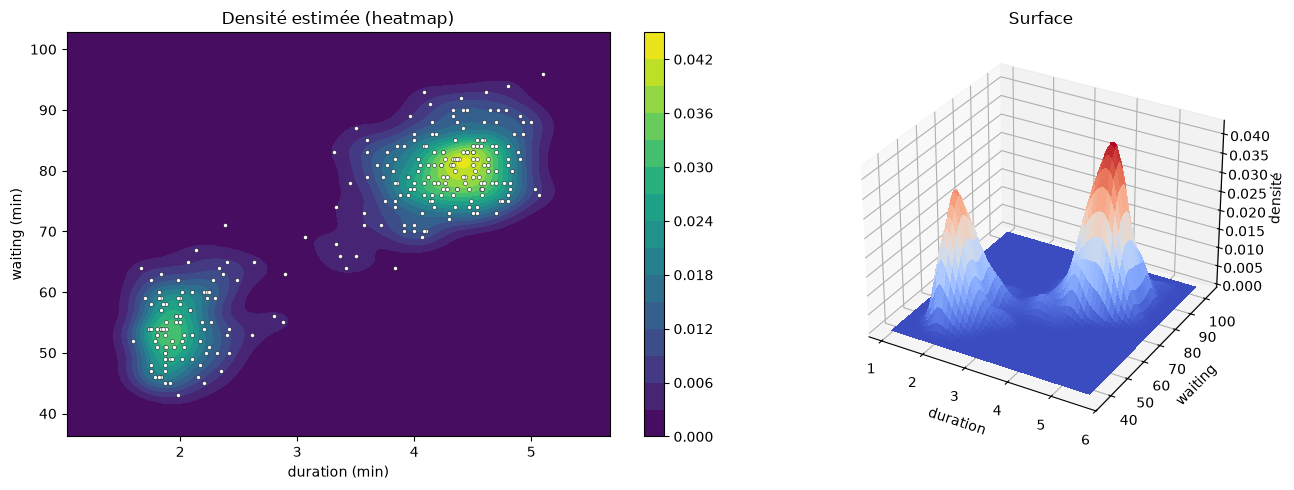

In [60]:
df = seaborn.load_dataset('geyser')
X_geyser = df[['duration', 'waiting']].values

# scikit-learn n'a qu'un h scalaire : on standardise pour que les deux variables aient la même échelle
scaler = StandardScaler().fit(X_geyser)
Xs = scaler.transform(X_geyser)

# Noyau gaussien, h choisi par validation croisée (vraisemblance)
cv2 = GridSearchCV(KernelDensity(kernel='gaussian'), {'bandwidth': np.logspace(-1.5, 0.3, 30)}, cv=10).fit(Xs)
kde2 = cv2.best_estimator_
print(f"h (variables standardisées) = {kde2.bandwidth:.3f}")

# Grille 2D dans l'espace standardisé
gx = np.linspace(Xs[:, 0].min() - 0.5, Xs[:, 0].max() + 0.5, 150)
gy = np.linspace(Xs[:, 1].min() - 0.5, Xs[:, 1].max() + 0.5, 150)
xx, yy = np.meshgrid(gx, gy)
dens = np.exp(kde2.score_samples(np.c_[xx.ravel(), yy.ravel()])).reshape(xx.shape)

# Retour aux unités d'origine (le jacobien du changement de variable garde une densité d'intégrale 1)
XX = xx * scaler.scale_[0] + scaler.mean_[0]
YY = yy * scaler.scale_[1] + scaler.mean_[1]
dens = dens / np.prod(scaler.scale_)
print("Intégrale de la densité sur la grille :", round(np.trapezoid(np.trapezoid(dens, XX[0], axis=1), YY[:, 0]), 3))

fig = plt.figure(figsize=(14, 5))
ax1 = fig.add_subplot(1, 2, 1)
cf = ax1.contourf(XX, YY, dens, levels=15, cmap='viridis')
ax1.scatter(*X_geyser.T, s=8, c='w', edgecolor='k', lw=0.3)
ax1.set_xlabel('duration (min)'); ax1.set_ylabel('waiting (min)'); ax1.set_title('Densité estimée (heatmap)')
fig.colorbar(cf, ax=ax1)

ax2 = fig.add_subplot(1, 2, 2, projection='3d')
ax2.plot_surface(XX, YY, dens, cmap='coolwarm', linewidth=0, antialiased=False)
ax2.set_xlabel('duration'); ax2.set_ylabel('waiting'); ax2.set_zlabel('densité'); ax2.set_title('Surface')
plt.tight_layout(); plt.show()


<div style="background-color: rgba(255, 255, 0, 0.15); padding: 8px;">

De manière cohérente avec le TP1, on retrouve bien notre densité bimodale avec nos deux groupes d'éruption.

Les deux variables sont positivement corrélées, ce qui se voit à l'orientation des modes.

Pour choisir le meilleur h possible, nous avons procédé par validation croisée.

</div>

### Partie 4 : Estimation par noyaux en 64D ! Un modèle génératif

Une fois la fonction de densité estimée par noyaux, nous pouvons échantillonner de cette loi. Ceci nous permet donc de générer "de fausses données". C'est ce que nous allons mettre en oeuvre sur un exemple simple avec des images. Estimer la densité nous permettra donc de créer un générateur d'images.


**Q1.** Pour cette dernière question, nous utiliserons le dataset *Digits* qui contient environ 1800 imagettes en niveaux de gris de taille 8 par 8, qui peuvent donc être représentées comme des vecteurs de taille 64. Ces imagettes représentent des numéros scannés de codes postaux.

- Estimer par noyaux de la densité en utilisant `scikit-learn`. Le choix du noyau et de la longueur de fenêtre sont laissés libres.
- Afficher 10 images du dataset, puis 10 images échantillonnées à partir de la loi estimée. On utilisera la méthode `.sample`.
- Commenter.

(a) KDE en 64D        : h = 1.83
(b) PCA : 84% de la variance conservée avec 15 composantes
    KDE après PCA     : h = 3.79


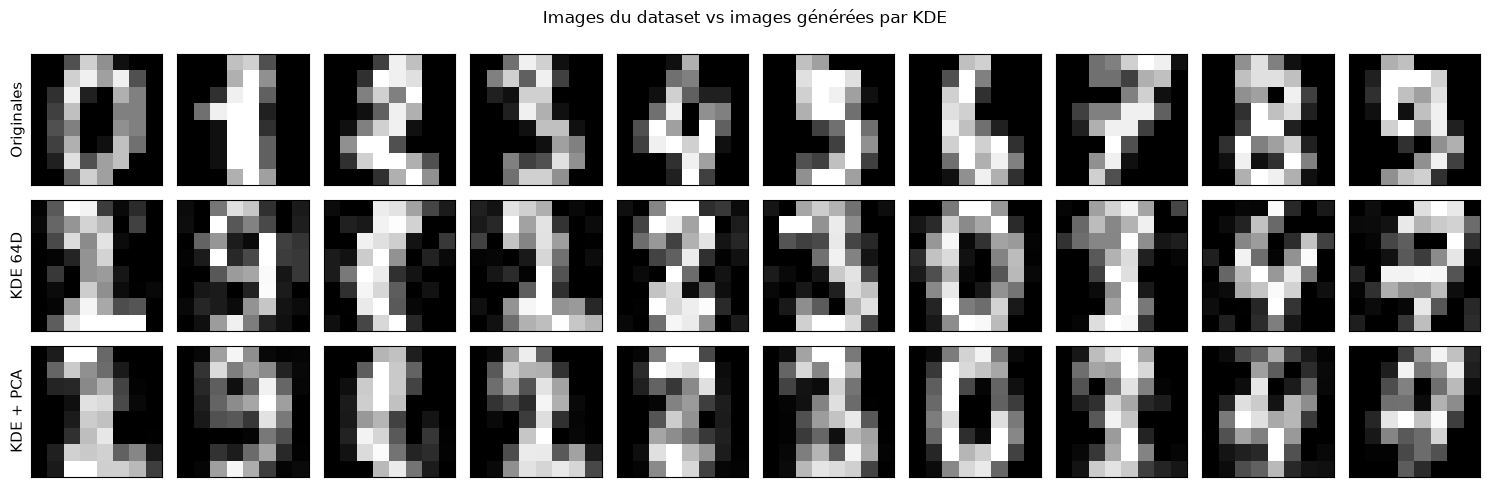

In [61]:
digits = load_digits()
Xd = digits.data
bw_grid = {'bandwidth': np.logspace(-1, 1, 20)}

# (a) KDE directement en dimension 64, h choisi par validation croisée
cv64 = GridSearchCV(KernelDensity(kernel='gaussian'), bw_grid, cv=5).fit(Xd)
kde64 = cv64.best_estimator_
print(f"(a) KDE en 64D        : h = {kde64.bandwidth:.2f}")
gen64 = np.clip(kde64.sample(10, random_state=0), 0, 16)

# (b) Variante : réduction par PCA, KDE dans l'espace réduit, puis retour en 64D
pca = PCA(n_components=15).fit(Xd)
print(f"(b) PCA : {pca.explained_variance_ratio_.sum():.0%} de la variance conservée avec 15 composantes")
Xp = pca.transform(Xd)
cvp = GridSearchCV(KernelDensity(kernel='gaussian'), bw_grid, cv=5).fit(Xp)
print(f"    KDE après PCA     : h = {cvp.best_estimator_.bandwidth:.2f}")
genpca = np.clip(pca.inverse_transform(cvp.best_estimator_.sample(10, random_state=0)), 0, 16)

# Affichage : 10 images du dataset, 10 échantillonnées en 64D, 10 échantillonnées après PCA
rows = [(Xd[:10], 'Originales'), (gen64, 'KDE 64D'), (genpca, 'KDE + PCA')]
fig, axes = plt.subplots(3, 10, figsize=(15, 5))
for r, (imgs, name) in enumerate(rows):
    for i in range(10):
        ax = axes[r, i]
        ax.imshow(imgs[i].reshape(8, 8), cmap='gray', vmin=0, vmax=16)
        ax.set_xticks([]); ax.set_yticks([])
    axes[r, 0].set_ylabel(name, fontsize=11)
fig.suptitle('Images du dataset vs images générées par KDE')
plt.tight_layout(); plt.show()


<div style="background-color: rgba(255, 255, 0, 0.15); padding: 8px;">

Échantillonner une loi estimée par noyaux gaussiens revient à choisir au hasard une image d'apprentissage $x_i$ puis à lui ajouter un bruit $\mathcal{N}(0, h^2 I_{64})$.

- En 64D : ($h \approx 1.8$ par validation croisée) : les images générées sont bruitées. Elles ont l'allure d'un chiffre manuscrit et certaines sont reconnaissables mais beaucoup restent ambiguës.
  
- Avec PCA : le bruit n'est ajouté que dans les 15 directions principales, et les autres directions sont supprimées. Les images ont un fond plus propre, mais ne sont pas nettement plus lisibles ici.
  
- Limites : le modèle ne crée pas vraiment de structure nouvelle, il mémorise les données et les perturbe. Il souffre de la curse of dimensionality (il faudrait beaucoup plus de données pour 64 dimensions, tous les points sont à la même distance les uns des autres).

</div>